In [ ]:
# 24B11IT002 - SVM 
#Import pandas to load and work with the CSV dataset
import pandas as pd

# Import train_test_split to divide the labeled data
# into training and testing sets
from sklearn.model_selection import train_test_split

# Import SVC (Support Vector Classifier)
# This is the SVM algorithm we will use
from sklearn.svm import SVC

In [4]:
# Load the training dataset
# Make sure train.csv is in the same folder as this notebook
train_data = pd.read_csv("../data/train.csv")

# Display the shape of the dataset
# Expected: (42000, 785)
print("Training data shape:", train_data.shape)

Training data shape: (42000, 785)


In [5]:
# X contains only the pixel values
# We remove the 'label' column because it is the answer
X = train_data.drop("label", axis=1)

# y contains the actual digit labels (0 to 9)
y = train_data["label"]

# Display the shapes
print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (42000, 784)
Labels shape: (42000,)


In [6]:
# Pixel values in the original dataset range from 0 to 255.
# Dividing by 255 converts them to values between 0 and 1.
# This helps the SVM work with appropriately scaled features.
X = X / 255.0

# Check the minimum and maximum values after normalization
print("Minimum pixel value:", X.min().min())
print("Maximum pixel value:", X.max().max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [7]:
# Import the train_test_split function
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing portions
X_train, X_test, y_train, y_test = train_test_split(
    X,                  # Pixel data
    y,                  # Digit labels
    test_size=0.2,      # Use 20% of the data for testing
    random_state=42,   # Makes the split reproducible
    stratify=y          # Keeps the proportion of digits balanced
)

# Display the resulting shapes
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (33600, 784)
X_test : (8400, 784)
y_train: (33600,)
y_test : (8400,)


In [8]:
# Create the Support Vector Machine classifier
svm_model = SVC(
    kernel="rbf",       # Radial Basis Function kernel
    C=10,               # Controls the trade-off between error and model complexity
    gamma="scale",      # Automatically determines a suitable gamma value
    random_state=42
)

# Display the model configuration
print(svm_model)

SVC(C=10, random_state=42)


In [9]:
# Train the SVM model using the training images
# X_train contains the pixel values
# y_train contains the correct digit labels
svm_model.fit(X_train, y_train)

# Print a message after training is complete
print("SVM training completed successfully!")

SVM training completed successfully!


In [10]:
# Use the trained SVM model to predict the digits
# of the test images
y_pred_svm = svm_model.predict(X_test)

# Display the first 10 predictions
print("First 10 predictions:", y_pred_svm[:10])

First 10 predictions: [1 8 6 9 5 7 6 7 7 7]


In [11]:
# Import the evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate the overall accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

# Calculate weighted precision for the 10 digit classes
svm_precision = precision_score(
    y_test,
    y_pred_svm,
    average="weighted"
)

# Calculate weighted recall
svm_recall = recall_score(
    y_test,
    y_pred_svm,
    average="weighted"
)

# Calculate weighted F1-score
svm_f1 = f1_score(
    y_test,
    y_pred_svm,
    average="weighted"
)

# Display all four metrics
print("SVM Accuracy :", svm_accuracy)
print("SVM Precision:", svm_precision)
print("SVM Recall   :", svm_recall)
print("SVM F1-Score :", svm_f1)

SVM Accuracy : 0.9791666666666666
SVM Precision: 0.9791557503978356
SVM Recall   : 0.9791666666666666
SVM F1-Score : 0.9791527265401562


In [12]:
# Error rate is the percentage of predictions
# that the SVM classified incorrectly.
svm_error_rate = 1 - svm_accuracy

# Calculate the number of incorrect predictions
svm_incorrect = (y_test != y_pred_svm).sum()

# Calculate the number of correct predictions
svm_correct = (y_test == y_pred_svm).sum()

# Display the results
print("SVM Error Rate:", svm_error_rate)
print("SVM Error Rate (%):", svm_error_rate * 100)

print("Correct predictions:", svm_correct)
print("Incorrect predictions:", svm_incorrect)

SVM Error Rate: 0.02083333333333337
SVM Error Rate (%): 2.083333333333337
Correct predictions: 8225
Incorrect predictions: 175


In [13]:
# Import the classification report
from sklearn.metrics import classification_report

# Display precision, recall and F1-score
# separately for each digit from 0 to 9
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98       827
           1       0.99      0.99      0.99       937
           2       0.98      0.98      0.98       835
           3       0.98      0.97      0.97       870
           4       0.98      0.98      0.98       814
           5       0.96      0.97      0.96       759
           6       0.98      1.00      0.99       827
           7       0.98      0.98      0.98       880
           8       0.98      0.97      0.98       813
           9       0.97      0.97      0.97       838

    accuracy                           0.98      8400
   macro avg       0.98      0.98      0.98      8400
weighted avg       0.98      0.98      0.98      8400



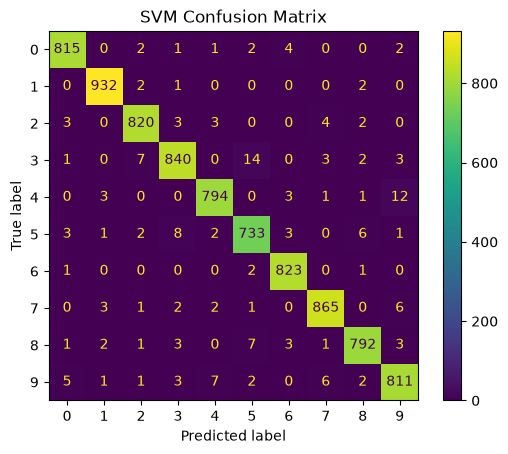

In [14]:
# Import tools required to create the confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred_svm)

# Create a visual representation of the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

# Display the matrix
disp.plot()

# Add a title
plt.title("SVM Confusion Matrix")

# Display the plot
plt.show()

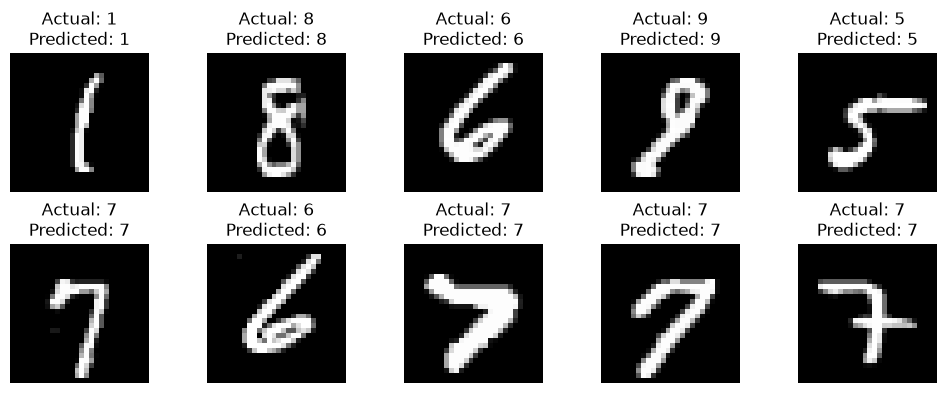

In [15]:
# Create a figure for displaying 10 test images
plt.figure(figsize=(10, 4))

# Display the first 10 test images
for i in range(10):

    # Convert the 784 pixels back into a 28 × 28 image
    image = X_test.iloc[i].values.reshape(28, 28)

    # Create a subplot
    plt.subplot(2, 5, i + 1)

    # Display the handwritten digit
    plt.imshow(image, cmap="gray")

    # Display actual and predicted labels
    plt.title(
        f"Actual: {y_test.iloc[i]}\n"
        f"Predicted: {y_pred_svm[i]}"
    )

    # Hide the axis
    plt.axis("off")

# Adjust spacing
plt.tight_layout()

# Display the images
plt.show()

In [16]:
# Import joblib for saving the trained model
import joblib

# Save the trained SVM model to a file
joblib.dump(svm_model, "svm_digit_model.pkl")

# Confirm that the model has been saved
print("SVM model saved successfully!")

SVM model saved successfully!
